# IMPORT LIBRARY

In [1]:
import os
import random
import datetime
import json
import pandas   as pd
import numpy    as np

from tqdm                               import tqdm
from preProcessingDataTurbofan          import PreProcessData
from utility.matpilotDraw               import MatPlot

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["turbofan"]

2025-02-20 11:09:33.403530: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-02-20 11:09:33.512722: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-02-20 11:09:33.512739: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-02-20 11:09:33.537055: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-20 11:09:34.065343: W tensorflow/stream_executor/platform/de

# LOADING DATA

In [2]:
plot               = MatPlot() 

# ----------------------    
# Reactor, Separator,Stripper
# ----------------------
np.random.seed(1)
random.seed(1)

preData     = PreProcessData(config=myConfig)
outputDir   = os.path.expanduser(preData.config["dataDir"])
rawData     = preData.loadDataFromTxtFormat(dir = outputDir, name="data/df_train.txt", printHead=False)
displayCl   = ['setting1', 'setting2', 'setting3', 's1', 's2', 's3',
                            's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14',
                            's15', 's16', 's17', 's18', 's19', 's20', 's21']
print(rawData["id"])


Process:20306||2025-02-20 11:09:35,042-INFO [preProcessingDataTurbofan.py:loadDataFromTxtFormat():344]:Loading data from H5 files ...
Process:20306||2025-02-20 11:09:35,104-INFO [preProcessingDataTurbofan.py:loadDataFromTxtFormat():353]:Finish loading data from H5 files!


0          1
1          1
2          1
3          1
4          1
        ... 
20626    100
20627    100
20628    100
20629    100
20630    100
Name: id, Length: 20631, dtype: int64


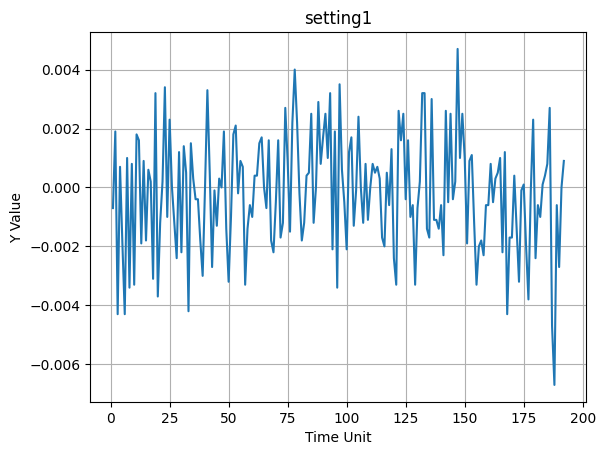

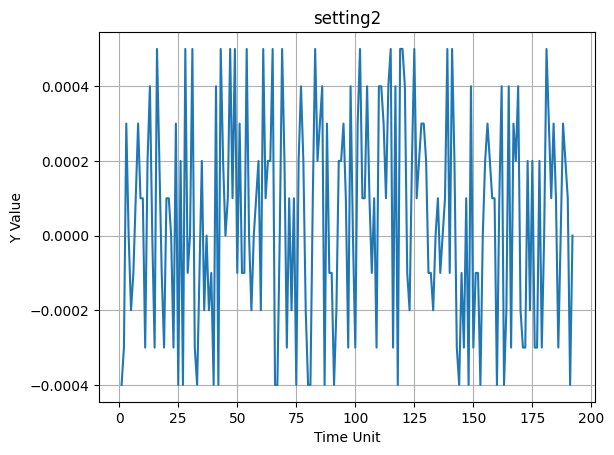

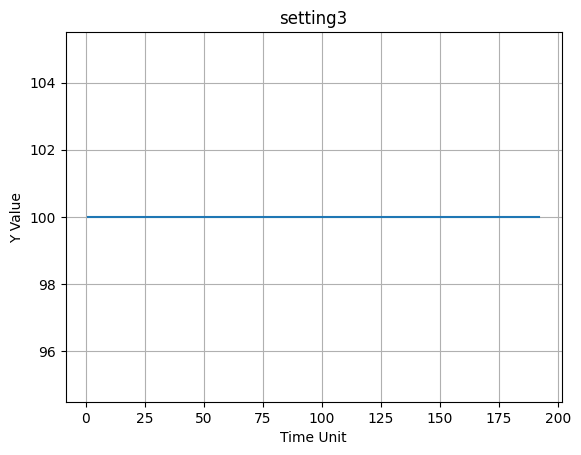

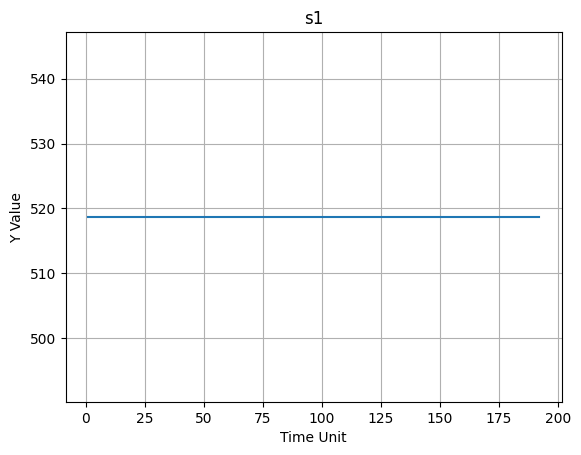

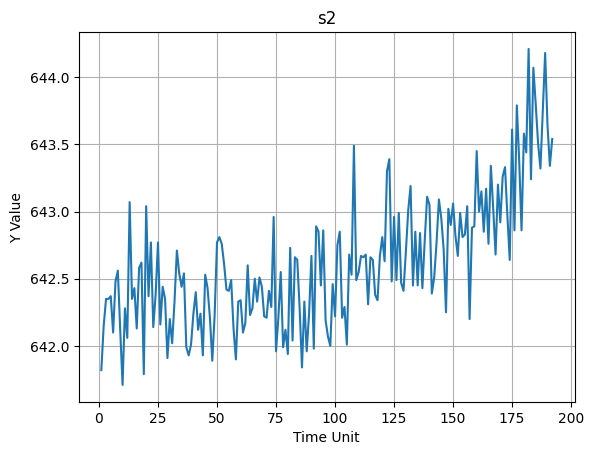

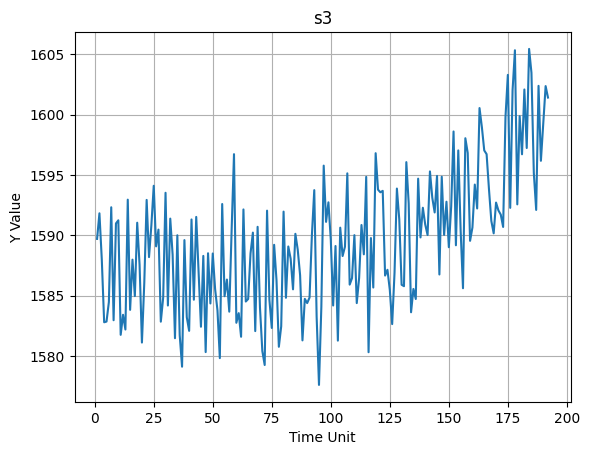

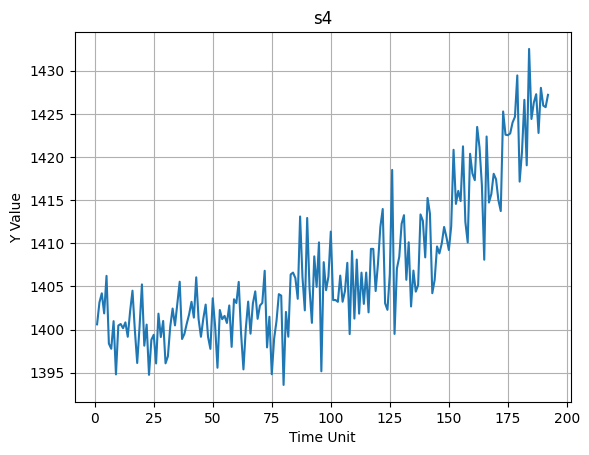

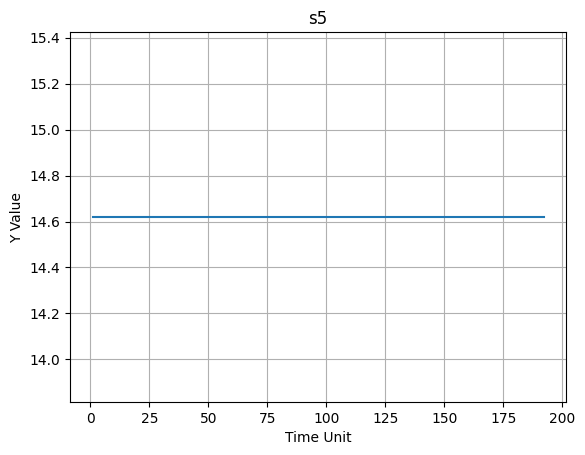

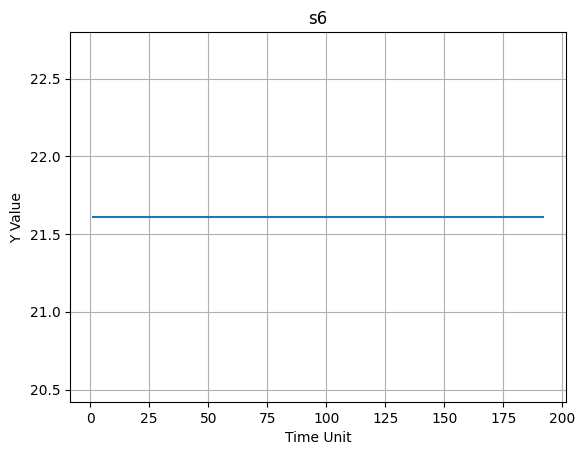

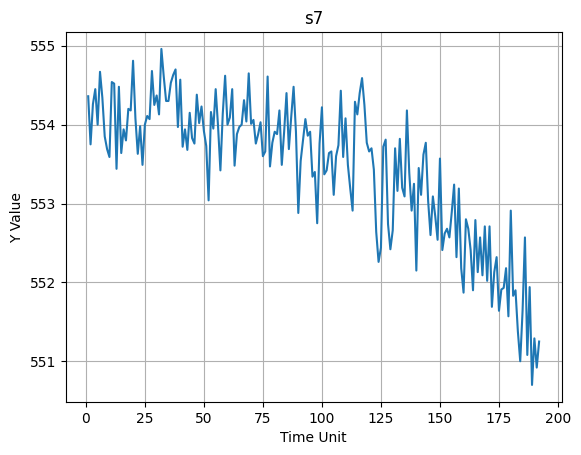

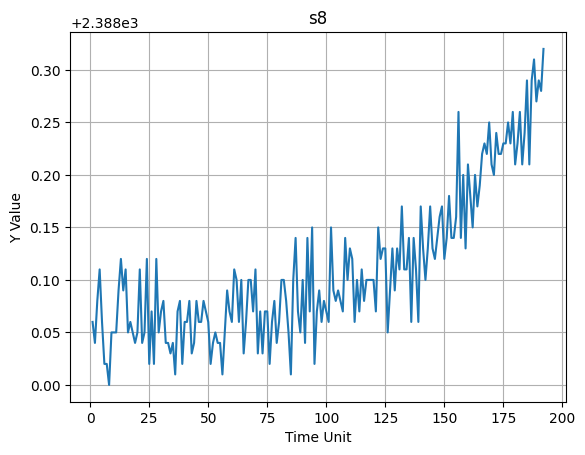

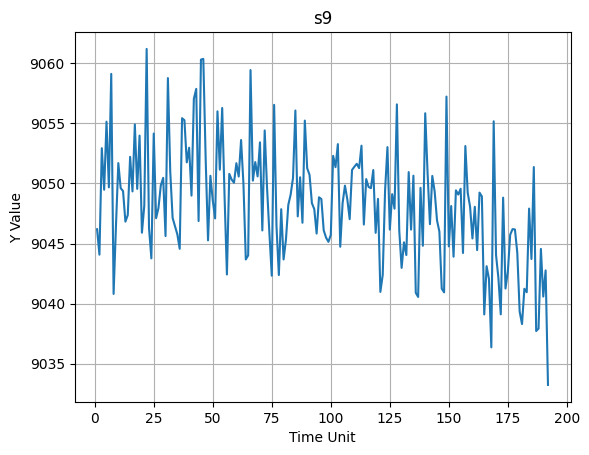

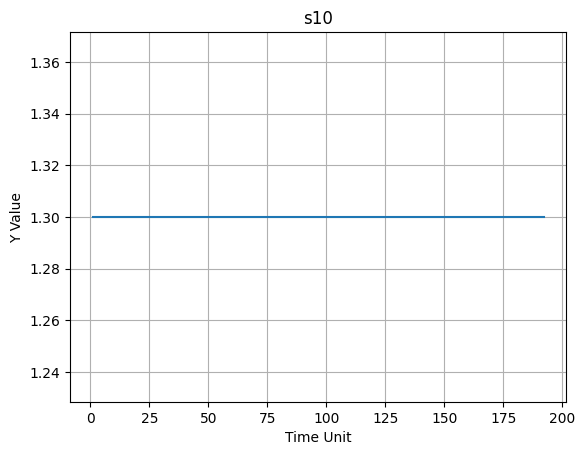

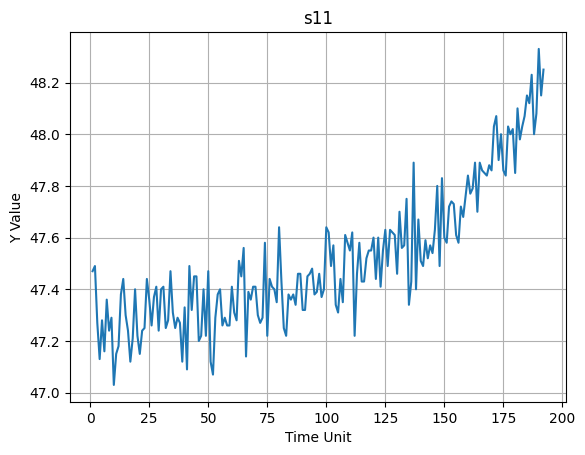

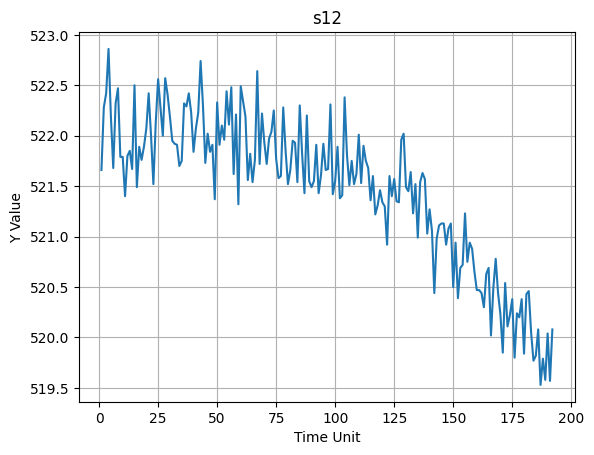

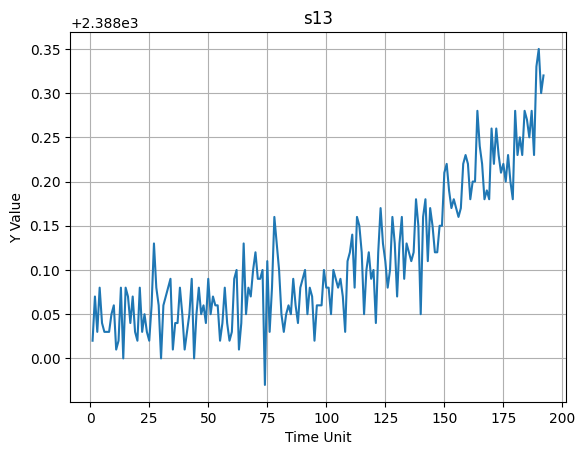

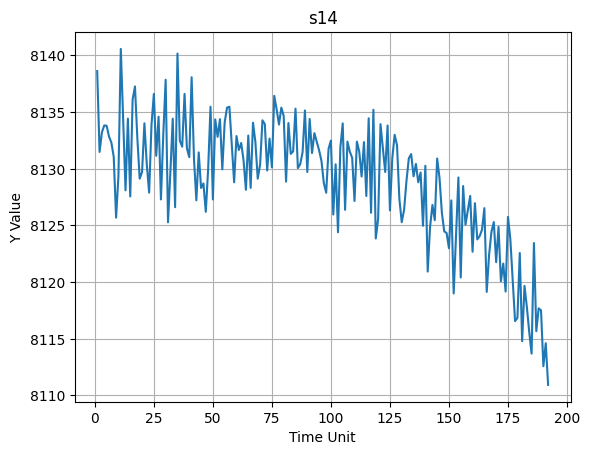

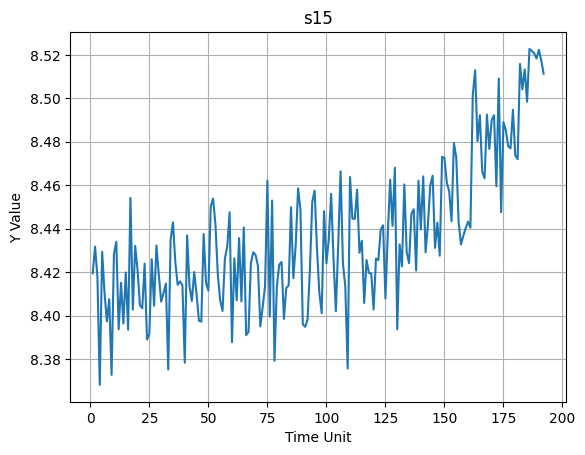

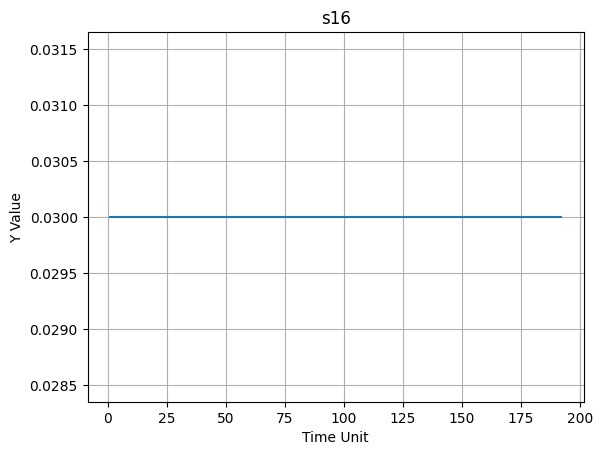

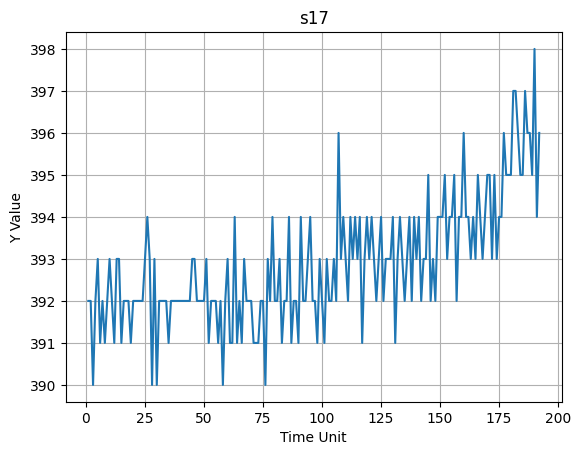

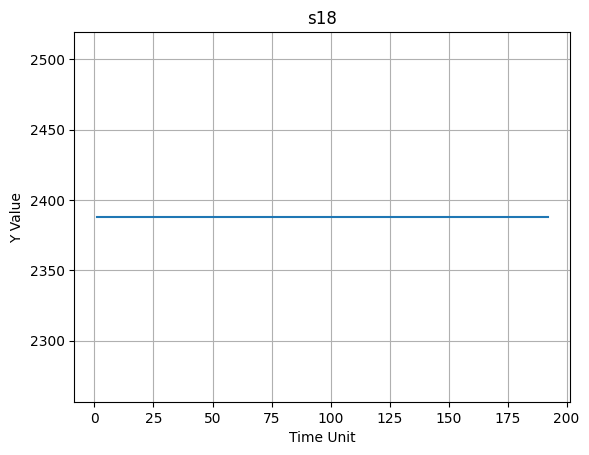

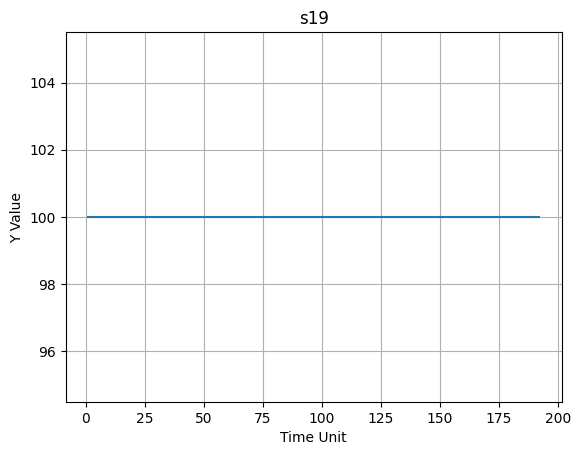

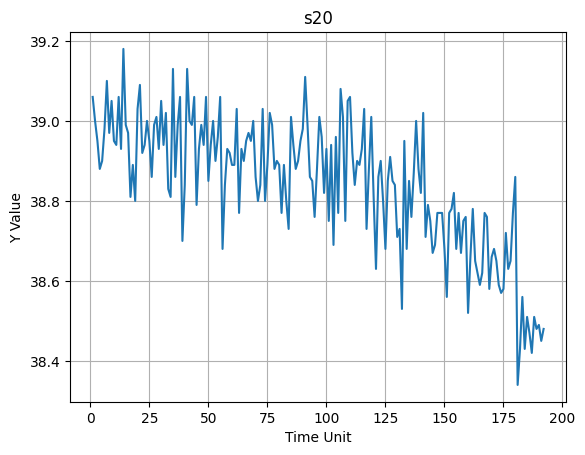

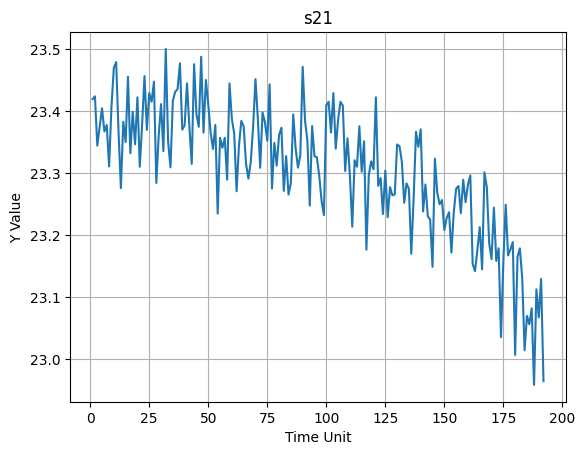

In [ ]:
for idx in range(1):
    curTrajectory = preData.getTrajectoryAt(inData = rawData, idxTrajectory= idx + 1)
    for idxHeadline in displayCl: 
        plot.draw2D(curTrajectory["cycle"],curTrajectory[idxHeadline], title=idxHeadline)


In [4]:
cleanData           = preData.cleanData(rawSignal               =   withoutInitRawData,
                                            columnName          =   preData.allWithoutLabel,
                                            getMovingAverage    =   True,
                                            flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

movedData           = preData.movingToPeak(cleanData)


NameError: name 'withoutInitRawData' is not defined

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= cleanData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
# Draw the data
print(cleanData)

### d. Normalize the data

In [ ]:
norData             = preData.normalizeDataAllModes(movedData)                # Normalize the data
# print(norData)

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData = norData, case = 2, idxTrajectory = 1)
for feature in preData.allHeadline:
    print(feature)
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
plot = MatPlot()

plot.subPlotMultiImg(inY = hi["reactor"],  numRow=20, numCol=5)

### g. Split into each sequence

In [ ]:

seqTrainXY   = preData.getTensorData(norData, component =   "reactor", case = 1 )
# seqValXY   = preData.splitAllDataIntoSequences(valXY)  

# print(seqTrainXY[0].shape,seqTrainXY[1].shape)
# print(seqTrainXY[0][2011][:,0])

### h. Visualize the tensor data

In [ ]:

# Creating an array from 1 to 3000
#time = np.arange(1, 10)
# t= 0:200
# plot.draw1D(yCoor=seqTrainXY[1][0:t])
plot.draw1D(yCoor=seqTrainXY[0][2011][:,3])
            


# 4. Model and training

### To tensor

In [ ]:
tensorTrainXY       = data.TensorDataset(seqTrainXY[0],seqTrainXY[1])
tensorValXY         = data.TensorDataset(seqValXY[0],seqValXY[1])

In [ ]:
train_loader = data.DataLoader(tensorTrainXY,
                                batch_size  =   config.batch_size,
                                shuffle     =   False, 
                                num_workers =   config.num_workers)
        
val_loader = data.DataLoader(  tensorValXY, 
                                batch_size  =   config.val_batch_size, 
                                shuffle     =   False, 
                                num_workers =   config.num_workers)